# State of the art: the calibration approaches of Tasche compared on S&P 2010 and 2011

- **Level:** 3, State of the art
- **Prerequisites:** notebooks 05 and 07 of this topic (the approaches and the IRB function)
- **Reading time:** about 35 minutes

## Objectives

By the end of this notebook you can:

- state what the research says about carrying a PD curve to a new period: Tasche's finding on scaling, and the other practices it lists;
- compare nine approaches on the same two forecast years by the PD each forecasts against the PD observed, the chi-square test of the implied default profile and the IRB risk weight;
- say which comparison separates the approaches and which does not, and why one year of 63 defaults cannot rank all of them;
- say what the product does and does not do on each practice.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.engines import pd_curve as pc
from riskvalidation.regulatory import capital_requirement

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.9.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

Two committed files of case C05, the calibration of a PD curve on the S&P corporate ratings of Tasche (2013) (licence class `derived-only`, so only rates, profiles and results are committed, never grade counts; https://doi.org/10.21314/jcr.2013.169): `data/derived/C05/sp-2010.json` and `data/derived/C05/sp-2011.json`. Each holds the 2009 estimation model, the forecast year's profile and observed PD, the curve of each of nine approaches (`approaches`), their committed tests (`tests`) and the capital impact (`impact`). The next cell loads them.

In [2]:
# Load the two artifacts (the notebook sits three folders below the repository root)
ROOT = Path("../../..").resolve()
C05 = ROOT / "data" / "derived" / "C05"
years = {y: json.loads((C05 / f"sp-{y}.json").read_text(encoding="utf-8")) for y in (2010, 2011)}
ids = list(years[2010]["outputs"]["approaches"])
names = {"A1-idp": "invariant default profile", "A2-iar": "invariant accuracy ratio", "A3-spd": "scaled PDs",
         "A4-slr": "scaled likelihood ratio", "B1-ilr": "invariant LR, PD known", "C1-ipc": "invariant PD curve (2009 unchanged)",
         "C2-ls": "conditional profiles, least squares", "C3-chi2": "conditional profiles, least chi-square", "C4-ilr": "invariant LR, profile known"}
for y, doc in years.items():
    o = doc["outputs"]
    print(y, "| baked by riskvalidation", doc["provenance"]["riskvalidation_version"], "| installed", rv.__version__, "| observed PD", round(o["pd1"], 6), "| defaults", o["n_defaults"], "of", o["n_obligors"])
print("approaches:", ids)

2010 | baked by riskvalidation 0.4.3 | installed 0.9.0 | observed PD 0.011409 | defaults 63 of 5522
2011 | baked by riskvalidation 0.4.3 | installed 0.9.0 | observed PD 0.007525 | defaults 44 of 5847
approaches: ['A1-idp', 'A2-iar', 'A3-spd', 'A4-slr', 'B1-ilr', 'C1-ipc', 'C2-ls', 'C3-chi2', 'C4-ilr']


## Method

**The comparison.** Tasche's nine approaches (notebook 05) sort by what is known when the new year starts: case 1 (the profile and the PD: A1 to A4), case 2 (only the PD: B1) and case 3 (only the profile: C1 to C4). Three readings compare them on the two forecast years:

1. **The PD each forecasts against the PD observed.** Case 1 and 2 approaches are given the PD; case 3 approaches have to produce it, from the profile alone. The ratio of the forecast to the observed PD says what not knowing it costs.
2. **The chi-square test of the implied default profile** (`pd.default_profile`): whether the defaults fell on the grades as the curve implies. It sees the shape, not the level.
3. **The average IRB risk weight** of the forecast portfolio under each curve: what the choice costs in capital.

One year has 63 defaults in 2010 and 44 in 2011 over 17 grades, and most grades have none or one. The tests cannot be expected to separate every pair. The next cell prints the forecast, the observed PD and their ratio for the nine approaches in both years.

In [3]:
# The forecast PD of each approach against the observed PD, both years
print(f"{'':10s}" + "".join(f"{y} forecast   {y} ratio   " for y in years))
for aid in ids:
    cells = []
    for y, doc in years.items():
        o = doc["outputs"]
        forecast = o["approaches"][aid]["pd"]
        cells.append(f"{100 * forecast:12.3f}%{forecast / o['pd1']:12.2f}   ")
    print(f"{aid:10s}" + "".join(cells))
print("observed PD (%):", {y: round(100 * doc["outputs"]["pd1"], 3) for y, doc in years.items()})
for y, doc in years.items():
    o = doc["outputs"]
    case3 = [o["approaches"][a]["pd"] / o["pd1"] for a in ("C1-ipc", "C2-ls", "C3-chi2", "C4-ilr")]
    print(y, "| case 3 forecasts as a multiple of the observed PD, lowest to highest:", round(min(case3), 2), "to", round(max(case3), 2))

          2010 forecast   2010 ratio   2011 forecast   2011 ratio   
A1-idp           1.141%        1.00          0.753%        1.00   
A2-iar           1.141%        1.00          0.753%        1.00   
A3-spd           1.141%        1.00          0.753%        1.00   
A4-slr           1.141%        1.00          0.753%        1.00   
B1-ilr           1.546%        1.36          0.868%        1.15   
C1-ipc           4.318%        3.78          3.751%        4.99   
C2-ls            4.799%        4.21          3.499%        4.65   
C3-chi2          5.347%        4.69          2.834%        3.77   
C4-ilr           5.377%        4.71          2.794%        3.71   
observed PD (%): {2010: 1.141, 2011: 0.753}
2010 | case 3 forecasts as a multiple of the observed PD, lowest to highest: 3.78 to 4.71
2011 | case 3 forecasts as a multiple of the observed PD, lowest to highest: 3.71 to 4.99


Cases 1 and 2 are given the PD, so their forecast equals it by construction (case 2 gives the PD under the observed profile, notebook 05, which differs). Case 3 has to infer the PD and gets it badly wrong in both years, 3.7 to 5.0 times too high: it starts from the 2009 PD of 3.99% and the profile alone does not tell that the year was calmer. Now the test of the implied default profile.

In [4]:
# The committed chi-square p-value and light of the implied default profile, by approach and year, and the ranking of case 1
tests = {y: {t["model_id"]: t for t in doc["tests"] if t["test_id"] == "pd.default_profile"} for y, doc in years.items()}
print(f"{'':10s}" + "".join(f"{'p ' + str(y):>10s}{'light':>8s}" for y in years))
for aid in ids:
    print(f"{aid:10s}" + "".join(f"{tests[y][aid]['p_value']:10.4f}{tests[y][aid]['light']:>8s}" for y in years))
case1 = ids[:4]
for y in years:
    ranked = sorted(case1, key=lambda a: -tests[y][a]["p_value"])
    print(y, "| case 1 by p-value, most to least consistent with the observed profile:", " > ".join(ranked))
print("amber or red approaches:", {y: [a for a in ids if tests[y][a]["light"] != "green"] for y in years})
print("Monte Carlo standard error of the p-values, largest:", round(max(t["extras"]["mc_standard_error"] for y in years for t in tests[y].values()), 5))

              p 2010   light    p 2011   light
A1-idp        0.0458   amber    0.7817   green
A2-iar        0.0791   green    0.8910   green
A3-spd        0.0425   amber    0.3696   green
A4-slr        0.1115   green    0.8199   green
B1-ilr        0.1011   green    0.8076   green
C1-ipc        0.0425   amber    0.3696   green
C2-ls         0.0335   amber    0.4215   green
C3-chi2       0.0293   amber    0.5095   green
C4-ilr        0.0291   amber    0.5153   green
2010 | case 1 by p-value, most to least consistent with the observed profile: A4-slr > A2-iar > A1-idp > A3-spd
2011 | case 1 by p-value, most to least consistent with the observed profile: A2-iar > A4-slr > A1-idp > A3-spd
amber or red approaches: {2010: ['A1-idp', 'A3-spd', 'C1-ipc', 'C2-ls', 'C3-chi2', 'C4-ilr'], 2011: []}
Monte Carlo standard error of the p-values, largest: 0.00158


The tests separate the years more than the approaches: in 2011 all nine are green (p from 0.37), and in 2010 six are amber: the invariant default profile, the scaled PDs and the four case 3 approaches. The scaled likelihood ratio, the invariant accuracy ratio and case 2 are green. In both years scaled PDs is last of case 1. With 44 or 63 defaults, mostly in the last grades, the test has little to tell the case 1 approaches apart beyond that; the ordering is read with that in mind. Now the cost in capital.

In [5]:
# The average IRB risk weight of the forecast portfolio under each curve, from the committed impact, and the spreads
irb = years[2010]["outputs"]["irb"]
print("IRB assumptions:", {k: v for k, v in irb.items() if k != "references"})
print(f"{'':10s}" + "".join(f"{'risk weight ' + str(y):>20s}" for y in years))
for aid in ids:
    print(f"{aid:10s}" + "".join(f"{years[y]['impact']['rw_' + aid]['value']:20.4f}" for y in years))
for y in years:
    imp = years[y]["impact"]
    print(y, "| spread of the four case 1 approaches:", f"{100 * imp['rw_spread_case1']['value']:.1f}%", "| the 2009 curve unchanged against the scaled likelihood ratio:", f"{100 * imp['rw_stale_vs_slr']['value']:.1f}%")
o = years[2010]["outputs"]
floor_hits = {aid: int(sum(p < irb["pd_floor"] for p in o["approaches"][aid]["curve"])) for aid in ids}
print("grades of 17 whose 2010 PD is below the 0.05% floor, by approach:", floor_hits)

IRB assumptions: {'regime': 'basel3', 'asset_class': 'corporate', 'lgd': 0.45, 'maturity': 2.5, 'pd_floor': 0.0005}
              risk weight 2010    risk weight 2011
A1-idp                  0.6092              0.5156
A2-iar                  0.5732              0.4939
A3-spd                  0.5878              0.5347
A4-slr                  0.5504              0.5052
B1-ilr                  0.6158              0.5326
C1-ipc                  0.9068              0.9263
C2-ls                   0.9548              0.8892
C3-chi2                 0.9836              0.8318
C4-ilr                  0.9850              0.8280
2010 | spread of the four case 1 approaches: 10.7% | the 2009 curve unchanged against the scaled likelihood ratio: 64.8%
2011 | spread of the four case 1 approaches: 8.3% | the 2009 curve unchanged against the scaled likelihood ratio: 83.3%
grades of 17 whose 2010 PD is below the 0.05% floor, by approach: {'A1-idp': 6, 'A2-iar': 7, 'A3-spd': 7, 'A4-slr': 7, 'B1-ilr': 7, '

## State of the art

### What the research found, and what the product does

- **Scaling the PDs is questionable.** Tasche (2013) shows that multiplying the old PD curve by a constant, the practice that is simple and widespread, is theoretically questionable, and that the invariant accuracy ratio by quasi moment matching and the scaled likelihood ratio perform much better. *Product:* all four are computed (notebook 05) and compared above; in these two years scaled PDs has the lowest p-value of case 1 in both (0.043 in 2010, 0.370 in 2011).
- **Carrying the old curve unchanged.** The invariant PD curve is what a bank does when it keeps last year's calibration. *Product:* it is computed as C1 and its price is shown: a forecast PD several times the observed and the largest risk weight.
- **Other rungs.** The research lists intercept recalibration, Platt scaling and isotonic regression as ways to calibrate a model's scores to PDs, and Bayesian priors for low-default portfolios. *Product:* these work on scores, not on a rating profile, and are outside the approaches compared here; the Jeffreys intervals of notebook 02 are the posterior of a Beta prior, and no further prior is fitted.
- **The comparison is a one-year result.** Two forecast years are two samples; the committed tests say which approach is consistent with the year's defaults, not which is right in general. The product states the limit and does not rank the approaches beyond it.

The figure draws the forecast over the observed PD for each approach in 2010, and the risk weights of both years.

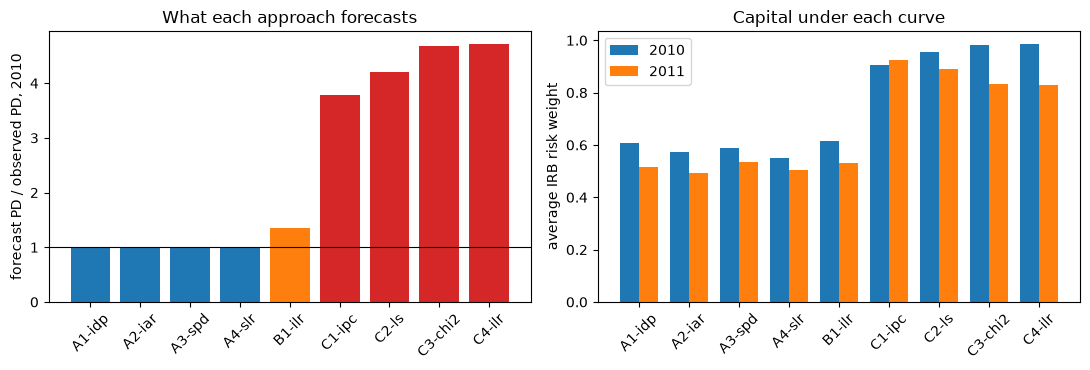

In [6]:
# Draw the forecast-to-observed ratio of 2010 and the risk weights of both years by approach
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.8))
o10 = years[2010]["outputs"]
left.bar(range(len(ids)), [o10["approaches"][a]["pd"] / o10["pd1"] for a in ids], color=["tab:blue"] * 4 + ["tab:orange"] + ["tab:red"] * 4)
left.axhline(1.0, color="black", linewidth=0.8)
left.set_xticks(range(len(ids)))
left.set_xticklabels(ids, rotation=45)
left.set_ylabel("forecast PD / observed PD, 2010")
left.set_title("What each approach forecasts")
width = 0.38
for k, y in enumerate(years):
    right.bar(np.arange(len(ids)) + (k - 0.5) * width, [years[y]["impact"]["rw_" + a]["value"] for a in ids], width, label=str(y))
right.set_xticks(range(len(ids)))
right.set_xticklabels(ids, rotation=45)
right.set_ylabel("average IRB risk weight")
right.set_title("Capital under each curve")
right.legend()
fig.tight_layout()
plt.show()

## Results

- **Forecast against observed.** The approaches of cases 1 and 2 are given the PD (case 2 gives 1.55% under the observed 2010 profile, 1.36 times the observed 1.14%, and 0.87% in 2011, 1.15 times 0.75%). The four case 3 approaches, which must infer it, forecast 3.78 to 4.71 times the observed PD in 2010 and 3.71 to 4.99 times in 2011.
- **The test of the implied default profile.** In 2011 all nine approaches are green (p from 0.37 to 0.89). In 2010 six are amber (p between 0.029 and 0.046: the invariant default profile 0.046, scaled PDs 0.043, the invariant PD curve 0.043 and the three other case 3 approaches 0.029 to 0.034), and the scaled likelihood ratio (0.112), case 2 (0.101) and the invariant accuracy ratio (0.079) are green. Within case 1 the order is scaled likelihood ratio, invariant accuracy ratio, invariant default profile, scaled PDs in 2010 and accuracy ratio, likelihood ratio, default profile, scaled PDs in 2011: scaled PDs is last in both. The Monte Carlo error of any p-value is at most 0.0016.
- **Capital.** In 2010 the average risk weight is 55.0% (scaled likelihood ratio), 57.3% (accuracy ratio), 58.8% (scaled PDs), 60.9% (default profile) and 61.6% (case 2), against 90.7% to 98.5% for case 3; in 2011 49.4% to 53.5% against 82.8% to 92.6%. The four case 1 approaches spread by 10.7% in 2010 and 8.3% in 2011; the unchanged 2009 curve asks 64.8% and 83.3% more than the scaled likelihood ratio. The PD floor of 0.05% binds in 6 or 7 of the 17 grades under the case 1 and 2 curves, so the good grades weigh the same whatever the approach.
- **What the comparison cannot say.** Two forecast years are two samples. The tests show that scaled PDs and the case 3 approaches fit the defaults of 2010 worse than the scaled likelihood ratio and the invariant accuracy ratio, and that nothing separates anything in 2011. They do not rank the approaches in general.

What this notebook does not show: how the curves are built (notebook 05) or how the IRB function turns a PD into capital (notebook 07).

## Summary

- The approaches that know the year's profile and PD fit the 2010 defaults better than scaling the PDs or keeping the old curve; in 2011 nothing separates them.
- Not knowing the PD (case 3) forecasts 3.7 to 5.0 times the observed PD and costs 65% to 83% more capital than the scaled likelihood ratio.
- The chi-square test sees the shape of a curve with few defaults and does not rank the approaches in general; the product says so.
- The research practices on scores (Platt, isotonic, intercept) and Bayesian priors are not run on a rating profile here.

**What to try next.** Read the 2009 targets of notebook 05 and ask which approach would have been chosen in advance; then read notebook 10.

## References

- Tasche, D. (2013), The art of probability-of-default curve calibration, Journal of Credit Risk 9(4), 63-103, Tables 6 to 8 and sections 4.2 to 4.4. https://doi.org/10.21314/jcr.2013.169
- BCBS, Basel Framework, CRE32, IRB approach: risk-weighted asset calculation (LGD, maturity and PD floor). https://www.bis.org/committees/bcbs/basel-framework/standard/cre/32/inforce/2023-01-01/published/2020-03-27
- Platt, J. (1999), Probabilistic outputs for support vector machines and comparisons to regularized likelihood methods, in Advances in Large Margin Classifiers, MIT Press, for the rung the research lists.